# Import Modules and Classes

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

from poset import PoSet
from simplicial_complex import SimplicialComplex

# Testing PoSets

## Good PoSet

In [2]:
p = PoSet(S = {1,2,3}, R = {(1,1), (2,2), (3,3), (1,2), (2,3), (1,3)})

## Bad PoSets


In [3]:
%%script false --no-raise-error
p_not_reflexive = PoSet(
    S = {1,2,3}, 
    R = {(1,1), (2,2), (1,2), (2,1)},
)

In [4]:
%%script false --no-raise-error
p_not_antisymmetric = PoSet(S = {1,2,3}, 
    R = {(1,1), (2,2), (3,3), (1,2), (2,1)},
)

In [5]:
%%script false --no-raise-error
p_not_transative = PoSet(
    S = {1,2,3}, 
    R = {(1,1), (2,2), (3,3), (1,2), (2,3)},
)

In [6]:
list(p.S)
list(p.R)

[(1, 2), (1, 1), (2, 3), (3, 3), (2, 2), (1, 3)]

In [7]:


test_complex = SimplicialComplex([{"a","b","c"}, {"c","d"}, {"e"}])
print(len(test_complex.S))
print(len(test_complex.R))
print(test_complex.R) # shows unsorted
#test_complex.S

10
24
{(frozenset({'a'}), frozenset({'b', 'a', 'c'})), (frozenset({'b'}), frozenset({'b', 'a', 'c'})), (frozenset({'b'}), frozenset({'b', 'a'})), (frozenset({'b', 'a', 'c'}), frozenset({'b', 'a', 'c'})), (frozenset({'a'}), frozenset({'a'})), (frozenset({'a'}), frozenset({'c', 'a'})), (frozenset({'b', 'c'}), frozenset({'b', 'c'})), (frozenset({'b'}), frozenset({'b', 'c'})), (frozenset({'c'}), frozenset({'c'})), (frozenset({'b', 'a'}), frozenset({'b', 'a'})), (frozenset({'b', 'a'}), frozenset({'b', 'a', 'c'})), (frozenset({'c', 'a'}), frozenset({'b', 'a', 'c'})), (frozenset({'e'}), frozenset({'e'})), (frozenset({'c'}), frozenset({'b', 'a', 'c'})), (frozenset({'c', 'a'}), frozenset({'c', 'a'})), (frozenset({'c'}), frozenset({'c', 'a'})), (frozenset({'d'}), frozenset({'c', 'd'})), (frozenset({'c'}), frozenset({'b', 'c'})), (frozenset({'d'}), frozenset({'d'})), (frozenset({'c'}), frozenset({'c', 'd'})), (frozenset({'b'}), frozenset({'b'})), (frozenset({'c', 'd'}), frozenset({'c', 'd'})), (f

In [8]:
print(test_complex)

lengths = [len(f)-1 for f in test_complex.S]
print(lengths)

#length_positions = [e for e, i in enumerate(lengths) if i == 0]
#print(length_positions)

uni_lengths = range(max(lengths)+1)
[*uni_lengths]

test_complex.n_simplices(0)



S = {{a}, {b}, {c}, {d}, {e}, {a, b}, {a, c}, {b, c}, {c, d}, {a, b, c}}
[1, 0, 1, 0, 1, 0, 2, 1, 0, 0]


{frozenset({'b'}),
 frozenset({'a'}),
 frozenset({'d'}),
 frozenset({'e'}),
 frozenset({'c'})}

In [9]:
test_complex.S
test_complex.R




{(frozenset({'a'}), frozenset({'a', 'b', 'c'})),
 (frozenset({'b'}), frozenset({'b'})),
 (frozenset({'b'}), frozenset({'a', 'b'})),
 (frozenset({'b'}), frozenset({'a', 'b', 'c'})),
 (frozenset({'a'}), frozenset({'a'})),
 (frozenset({'a'}), frozenset({'a', 'c'})),
 (frozenset({'b'}), frozenset({'b', 'c'})),
 (frozenset({'c'}), frozenset({'c'})),
 (frozenset({'c'}), frozenset({'a', 'c'})),
 (frozenset({'c'}), frozenset({'b', 'c'})),
 (frozenset({'c'}), frozenset({'c', 'd'})),
 (frozenset({'b', 'c'}), frozenset({'b', 'c'})),
 (frozenset({'a', 'b'}), frozenset({'a', 'b'})),
 (frozenset({'a', 'b'}), frozenset({'a', 'b', 'c'})),
 (frozenset({'c'}), frozenset({'a', 'b', 'c'})),
 (frozenset({'a', 'c'}), frozenset({'a', 'c'})),
 (frozenset({'a', 'c'}), frozenset({'a', 'b', 'c'})),
 (frozenset({'b', 'c'}), frozenset({'a', 'b', 'c'})),
 (frozenset({'a', 'b', 'c'}), frozenset({'a', 'b', 'c'})),
 (frozenset({'e'}), frozenset({'e'})),
 (frozenset({'d'}), frozenset({'d'})),
 (frozenset({'d'}), frozen

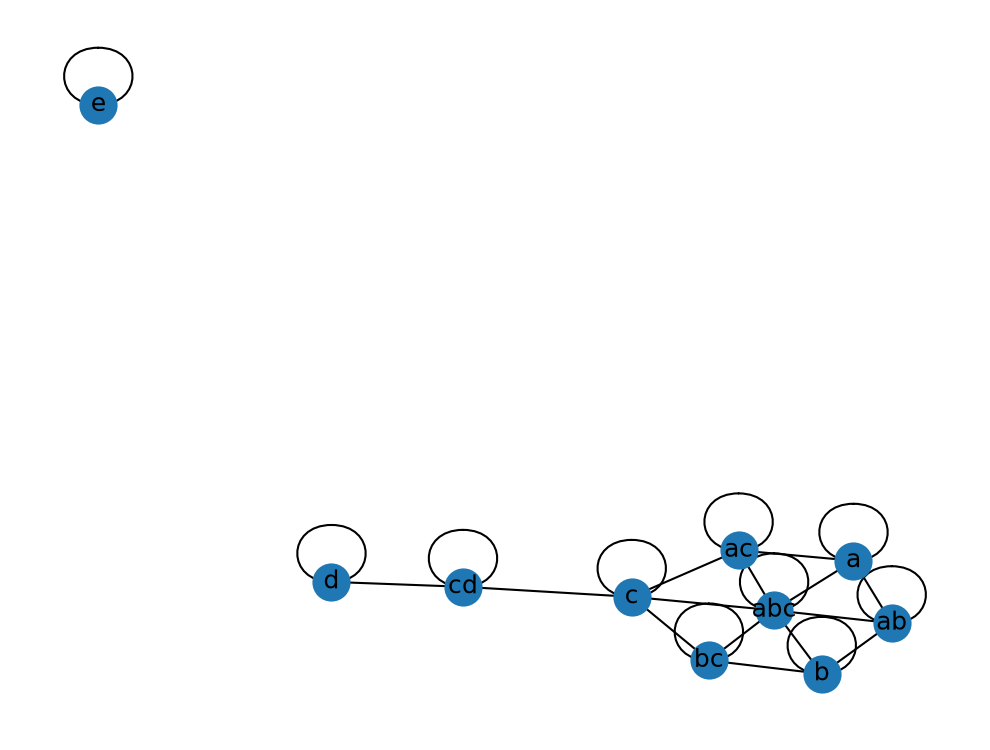

In [10]:
g = nx.Graph()
g.add_nodes_from(test_complex.S)
g.add_edges_from(test_complex.R)
my_labels = {x: test_complex._nice_label(x) for x in test_complex.S}

nx.draw(g, labels = my_labels, with_labels=True)

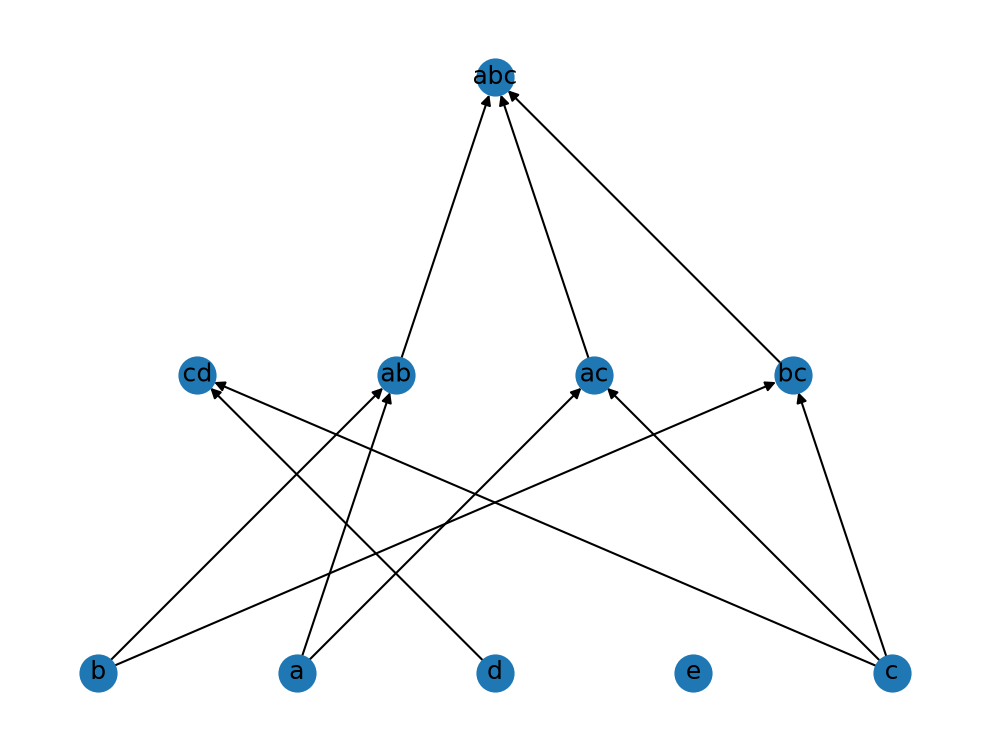

In [11]:
G = nx.DiGraph(test_complex.R)

G.remove_edges_from(list(nx.selfloop_edges(G)))

H = nx.transitive_reduction(G)

for n in H.nodes:
    H.nodes[n]["level"] = len(n)

pos = nx.multipartite_layout(H, subset_key="level", align="horizontal")

my_labels = {x: test_complex._nice_label(x) for x in test_complex.S}

nx.draw(H, pos, labels=my_labels, with_labels=True)


False

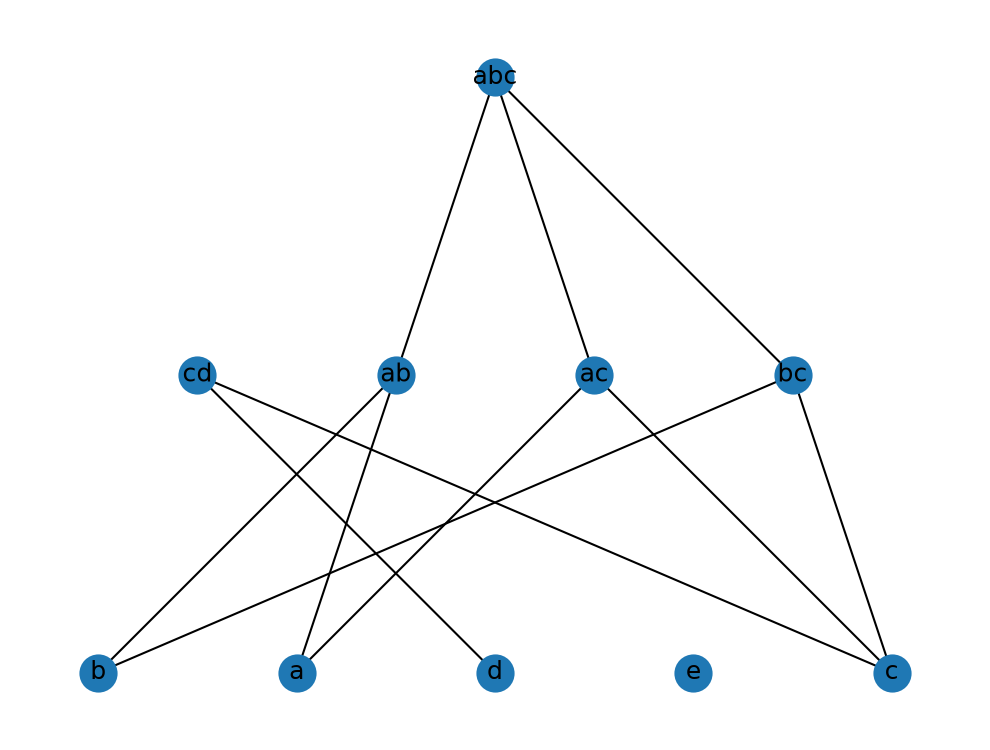

In [23]:
test_complex.dim()
test_complex.boundary_k("abc")

H2 = H.to_undirected()
nx.draw(H2, pos=pos, labels =  my_labels, with_labels = True)

nx.is_connected(H2)

In [75]:
set(test_complex.S) == set(H.nodes)
my_labels

{frozenset({'c'}): 'c',
 frozenset({'a', 'b'}): 'ab',
 frozenset({'e'}): 'e',
 frozenset({'a', 'c'}): 'ac',
 frozenset({'d'}): 'd',
 frozenset({'b'}): 'b',
 frozenset({'a'}): 'a',
 frozenset({'c', 'd'}): 'cd',
 frozenset({'b', 'c'}): 'bc',
 frozenset({'a', 'b', 'c'}): 'abc'}